<a href="https://colab.research.google.com/github/Niklas-Hy/Deeplearning/blob/main/Exercise_6_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 6.3: Neural Networks in Keras

In [42]:
import numpy as np
import matplotlib.pyplot as plt

# See https://keras.io/
# for extennsive documentation
import tensorflow as tf
from tensorflow import keras

from keras.models import Sequential
from keras.layers import Dense

plt.style.use("seaborn-v0_8")

Let us visit the problem of wine quality prediction previously encountered one final time. After linear regression and a self-made network, we can now explore the comfort provided by the Keras library.

In [43]:
# The code snippet below is responsible for downloading the dataset to
# Google. You can directly download the file using the link
# if you work with a local anaconda setup
!wget -nc https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv --no-check-certificate

File ‘winequality-white.csv’ already there; not retrieving.



In [44]:
# load all examples from the file
data = np.genfromtxt("winequality-white.csv", delimiter=";", skip_header=1)

print(f"{data.shape = } \n")

# Prepare for proper training
rng = np.random.default_rng(1234)
rng.shuffle(data)  # randomly sort examples

# take the first 3000 examples for training
# (remember array slicing from last week)
X_train = data[:3000, :11]  # all features except last column
y_train = data[:3000, 11]  # quality column

# and the remaining examples for testing
X_test = data[3000:, :11]  # all features except last column
y_test = data[3000:, 11]  # quality column

print("First example:")
print("Features:", X_train[0])
print("Quality:", y_train[0])

data.shape = (4898, 12) 

First example:
Features: [6.8000e+00 1.9000e-01 7.1000e-01 1.7500e+01 4.2000e-02 2.1000e+01
 1.1400e+02 9.9784e-01 2.8500e+00 5.0000e-01 9.5000e+00]
Quality: 6.0


Below is the simple network from exercise 4.1 implemented using Keras. In addition to the network we define the loss function and optimiser.

In [45]:
# See: https://keras.io/api/models/sequential/ and
# https://keras.io/api/layers/core_layers/dense/
# We can use the Sequential class to very easiliy
# build a simple architecture

norm = keras.layers.Normalization()
norm.adapt(X_train)

model = Sequential()

# 11 inputs, 20 outputs, relu
model.add(keras.Input(shape=(11,)))
model.add(norm)

model.add(Dense(64, activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(16, activation='relu'))
#model.add(Dense(20, activation='relu'))   # only this one hidden layer


# 20 inputs (automatically detected by Keras), 1 output, linear activation
model.add(Dense(1, activation='linear'))


#opt = keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
opt = keras.optimizers.Adam(learning_rate=0.001)

#opt = keras.optimizers.SGD(learning_rate=0.01)

# Set loss function and optimiser algorithm
model.compile(
    loss='mse',   # mean squared error
    optimizer=opt # stochastic gradient descent

)

# Training and evaluation below

The code below trains the network for 5 epochs using the loss function and optimiser defined above. Each example is individually passed to the network

In [46]:
history = model.fit(X_train, y_train,
                    validation_data=(X_test, y_test),
                    epochs=30, batch_size=5)


Epoch 1/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 4.0128 - val_loss: 1.2415
Epoch 2/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.8665 - val_loss: 0.6883
Epoch 3/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6117 - val_loss: 0.5837
Epoch 4/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5533 - val_loss: 0.6010
Epoch 5/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5331 - val_loss: 0.5353
Epoch 6/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.5128 - val_loss: 0.5574
Epoch 7/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.5062 - val_loss: 0.5209
Epoch 8/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5071 - val_loss: 0.6190
Epoch 9/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.4921 - val_loss: 0.5617
Epoch 10/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4823 - val_loss: 0.5785
Epoch 11/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4750 - val_loss: 0.5505
Epoch 12/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step

In [47]:
# The history object returned by the model training above
# contains the values of the loss function (the mean-squared-error)
# at different epochs
# We discard the first epoch as the loss value is very high,
# obscuring the rest of the distribution
train_loss = history.history["loss"][1:]
test_loss = history.history["val_loss"][1:]

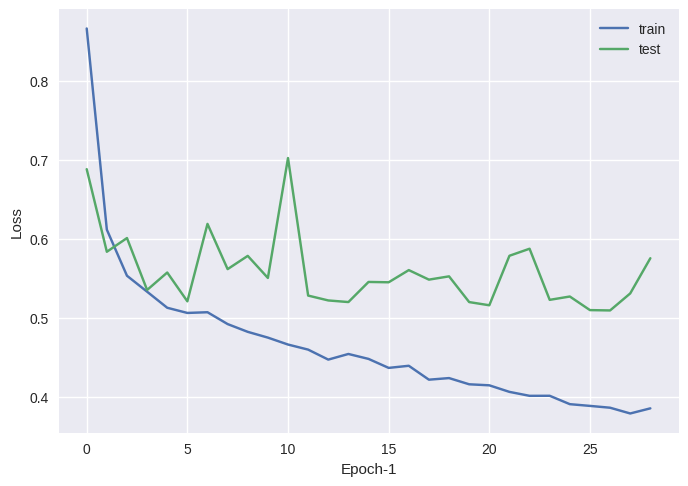

In [48]:
# Prepare and plot loss over time
plt.plot(train_loss,label="train")
plt.plot(test_loss,label="test")
plt.legend()
plt.xlabel("Epoch-1")
plt.ylabel("Loss")
plt.show()

60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Correlation coefficient: 0.6020358530709934


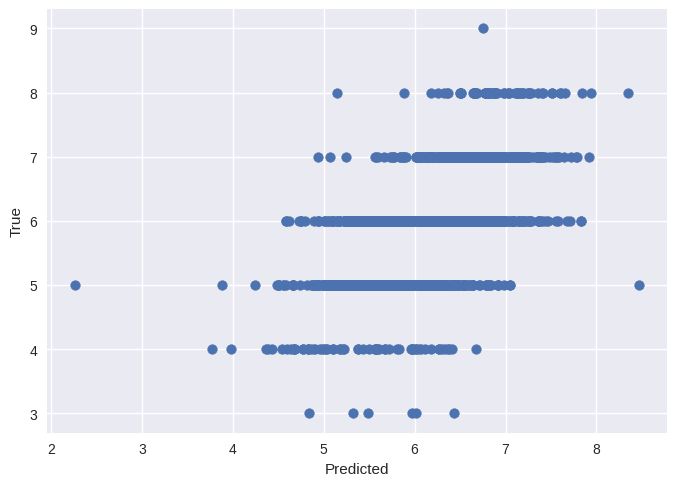

In [49]:
# After the training:

# Prepare scatter plot
y_pred = model.predict(X_test)[:,0]

print("Correlation coefficient:", np.corrcoef(y_pred,y_test)[0,1])
plt.scatter(y_pred,y_test)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

Using the Adam optimiser with lr=0.001, epoch = 300 and batch size = 32. Model size of 3 hidden layers (64,32,16) gave a correlation cof of 0.5299.

With normalized inputs, Adam (lr = 0.001), layers 64-32-16, batch size 32 and 300 epochs, the loss drops quickly in the first ~10 epochs. After about 20–30 epochs the test loss reaches its minimum (~0.51) and then rises to ~0.72, while the training loss keeps decreasing to ~0.14. This is clear overfitting: the large network memorizes the training data. Fewer epochs (around 30), a smaller network or regularization (e.g. dropout or L2) would give better test performance.





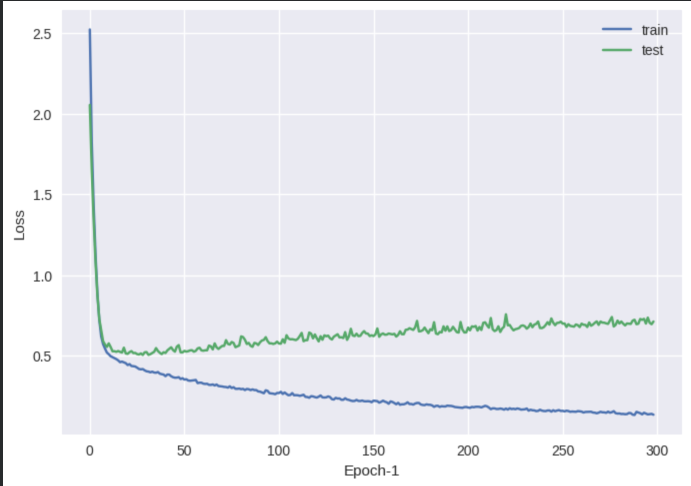

With Adam, one hidden layer of 20 ReLU nodes, batch size 5 and 30 epochs, the training and test loss decrease together and level out at ~0.48 and ~0.51. The two curves stay close, so there is no overfitting. Compared to the larger 64-32-16 network, the test loss is about the same as the best test loss of the larger network, but it doesn’t increase afterwards. Adding more layers therefore doesn’t improve the result on this noisy dataset with only 11 features. It mainly makes the model overfit faster. And a correlation cof 0.5827308866180432




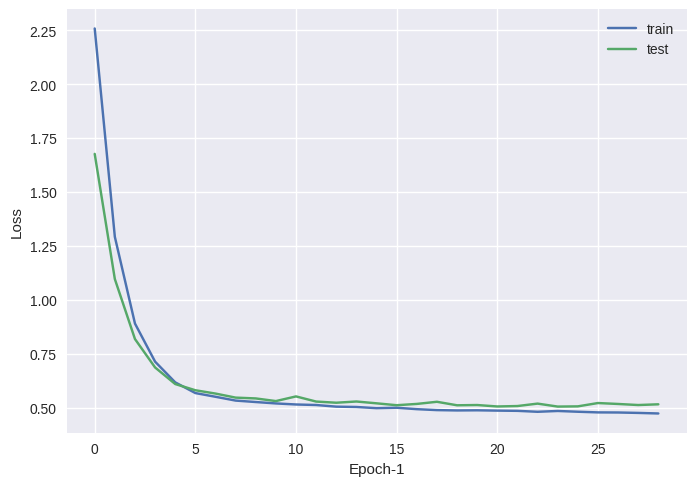


SGD with momentum 0.9 (lr = 0.01, layers 64-32-16, batch 32, 300 epochs) converges very fast: the test loss reaches its minimum (~0.48) after only about 5–10 epochs. After that the training loss keeps falling to ~0.07 while the test loss rises to ~0.65, which is strong overfitting. The momentum term keeps part of the previous update, so the optimizer speeds up in consistent directions. That helps early on, but it also lets the large network memorize the training data quickly. Compared to Adam it reached a similar best test loss, overfitted more strongly, and the test loss fluctuated more. With a correlation cof 0.5762151461505371





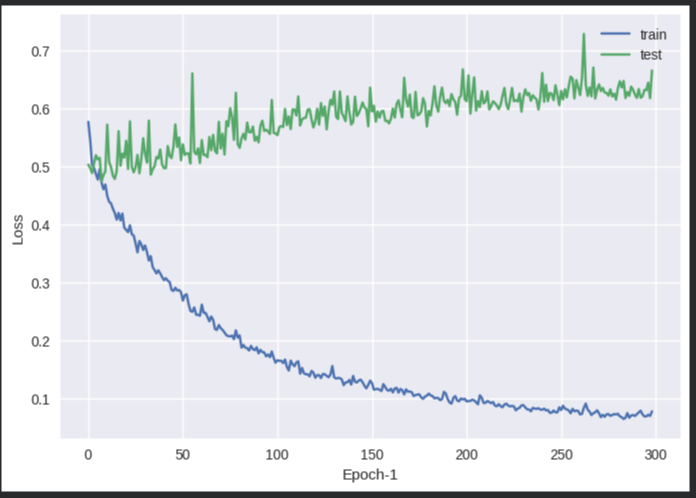

With Adam, layers 64-32-16, batch size 5 and 30 epochs, the training loss decreases to ~0.38 while the test loss fluctuates between ~0.51 and ~0.70 and ends at ~0.58. Compared to the single hidden layer with the same settings (test ~0.51, smooth curve), the extra layers fit the training data better but generalize worse: the gap between train and test loss grows, which shows overfitting. The small batch size makes the updates noisy, which together with the larger network gives the unstable test loss. For this dataset the smaller network is the better choice. and a Correlation coefficient: 0.6020358530709934


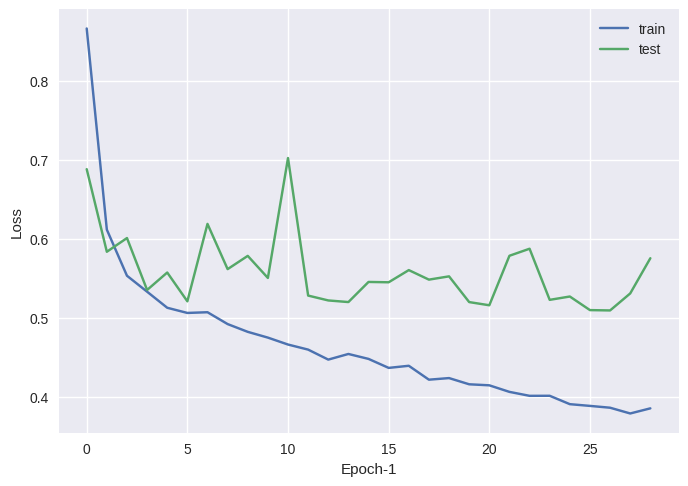

Plain SGD (lr = 0.01, no momentum) learns more slowly: after 300 epochs the training loss is 0.20, compared to 0.07 with momentum and 0.14 with Adam. The test loss reaches its minimum (0.48) after about 15–30 epochs and then slowly increases, so the model still overfits, but less than with momentum. The test loss shows large spikes, because each update depends only on the current mini-batch, which makes training noisy.




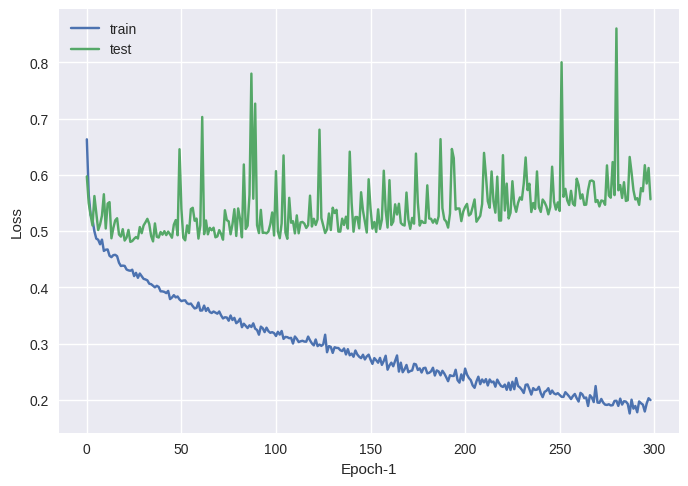

In [50]:
np.corrcoef(y_pred,y_test)

array([[1.        , 0.60203585],
       [0.60203585, 1.        ]])

All optimizers reach a similar best test loss (~0.48–0.51). Momentum is fastest but overfits most, Adam is fast and smooth, and plain SGD is slowest and noisiest. With 300 epochs all large networks overfit, so about 30 epochs is enough. Smaller batches (5) give more updates per epoch and faster learning but noisier curves. The best result was Adam with 64-32-16 layers, batch size 5 and 30 epochs (r = 0.602).


# Problems

* Use the notebook as starting point. It already contains the simple network from Exercise 4.1 implemented in Keras.

* Currently, SGD is used without momentum. Try training with a momentum term. Replace SGD with the Adam optimizer and train using that. (See: https://keras.io/api/optimizers/)
* Add two more hidden layers to the network (you can choose the number of nodes but make sure to apply the ReLu activation function after each) and train again.
* Test differet numbers of examples (i.e. change the batch batch size) to be simulataneously used by the network.
* (bonus) optimize the network architecture to get the best correlation coefficient. (Let's see who gets the most out of the data).